# 02 - Checking the Extracted Features

**Goal:** Find out which of the extracted features show a difference between real and fake clips, and whether any look too good to be true.

*Note:* We use the 2019 LA **train** and **dev** features at 4 s, with silence trimmed. The 2019 **eval** and all of the 2021 data stay untouched until the final test.

## Contents

1. Setup
2. Turning Each Feature into Numbers per Clip
3. Loading the Features
4. How Well Does Each Number Separate Real from Fake?
5. Do the Scores Hold on Dev?
6. Features to Watch
7. Summary

## Setup

Loads the libraries and the project's shared code, and defines the names used throughout.

- **`autoreload`**: if you edit a file in `src/`, the notebook picks up the change without restarting.
- **`src/data.py`**: `load_features` joins the saved batches of one feature and returns the features with their labels.
- **`src/features.py`**: `FEATURES` lists the eight feature groups.
- **`REAL` / `FAKE`**: the label numbers (0 = real, 1 = fake), as in the first notebook.

In [10]:
# Re-import edited files from src/ automatically, and show plots inside the notebook
%load_ext autoreload
%autoreload 2
%matplotlib inline

# Let the notebook import our shared code from src/
import sys
sys.path.insert(0, "../src")

# Tables, numbers and plots
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Score for how well one number separates real from fake
from sklearn.metrics import roc_auc_score

# Project code: audio settings, the feature list, and the feature loader
from config import CLIP_SECONDS, N_LFCC, N_MELS, N_MFCC
from data import load_features
from features import FEATURES

# Label numbers, plus a readable name and plot color for each
REAL, FAKE = 0, 1
NAMES = {REAL: "real", FAKE: "fake"}
COLORS = {REAL: "tab:blue", FAKE: "tab:red"}

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Turning Each Feature into Numbers per Clip

Most features are a grid: one row per coefficient or frequency band, one column per moment in time. To compare real and fake we boil each row down to two numbers per clip: its **average** over time and its **spread** (standard deviation) over time. The spread is how much the feature changes during the clip.

Jitter, shimmer and the noise features are already one number per clip, so they are used as they are. For pitch we also add the **voiced fraction**: the share of frames where a pitch was found.

In [11]:
# One name per row of each feature, in the order the rows are saved
ROW_NAMES = {
    "mfcc": [f"{p}mfcc{i}" for p in ("", "d_", "dd_") for i in range(N_MFCC)],
    "lfcc": [f"lfcc{i}" for i in range(N_LFCC)],
    "logmel": [f"logmel{i}" for i in range(N_MELS)],
    "cqt": [f"cqt{i}" for i in range(84)],
    "spectral": ["centroid", "flatness", "rolloff", "flux"],
    "pitch": ["f0", "voiced_prob"],
    "jitter_shimmer": ["jitter", "shimmer"],
    "noise": ["noise_mean_db", "noise_std_db"],
}


def summarize(feature, x):
    """One table row per clip. Columns are named "<feature>:<row>:<mean or std>"."""
    names = ROW_NAMES[feature]
    if x.ndim == 2:  # already one number per clip
        return pd.DataFrame(x, columns=[f"{feature}:{n}" for n in names])

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # pitch is NaN where there is no pitch
        mean, std = np.nanmean(x, axis=2), np.nanstd(x, axis=2)

    cols = {}
    for i, n in enumerate(names):
        cols[f"{feature}:{n}:mean"] = mean[:, i]
        cols[f"{feature}:{n}:std"] = std[:, i]
    if feature == "pitch":
        cols["pitch:voiced_fraction"] = (~np.isnan(x[:, 0, :])).mean(axis=1)
    return pd.DataFrame(cols)

## Loading the Features

Each feature is loaded, boiled down with the function above, and the full grid is thrown away to save memory.

In [12]:
summary, labels = {}, {}
for split in ("train", "dev"):
    parts = []
    for feature in FEATURES:
        x, labels[split] = load_features(feature, split, CLIP_SECONDS)
        parts.append(summarize(feature, x))
    summary[split] = pd.concat(parts, axis=1).astype(np.float32)
    print(f"{split}: {summary[split].shape[0]:,} clips, {summary[split].shape[1]} numbers per clip")

train: 25,380 clips, 505 numbers per clip
dev: 24,844 clips, 505 numbers per clip


In [13]:
# How many numbers each feature turned into, and how many are missing
group = pd.Series([c.split(":")[0] for c in summary["train"].columns], index=summary["train"].columns)
pd.DataFrame({
    "numbers per clip": group.value_counts(),
    "missing (train)": summary["train"].isna().mean().groupby(group).mean().round(3),
}).loc[list(FEATURES)]

,numbers per clip,missing (train)
mfcc,120,0.000
lfcc,40,0.000
logmel,160,0.000
cqt,168,0.000
spectral,8,0.000
pitch,5,0.001
jitter_shimmer,2,0.000
noise,2,0.000


## How Well Does Each Number Separate Real from Fake?

Each number is used **on its own** to separate real from fake, the same score as the silence check in the first notebook. It is 0.5 if the number tells us nothing and 1.0 if it separates the labels perfectly.

Two things to look for:

- **Close to 0.5:** the number carries no information about real versus fake.
- **Above about 0.9:** suspiciously good. A single number rarely separates this well, so it may be a shortcut in the data rather than a property of the voice.

In [14]:
def auc_per_column(table, y):
    """Raw score per column: above 0.5 means higher values are more likely fake."""
    out = {}
    for col in table.columns:
        v = table[col].to_numpy()
        ok = np.isfinite(v)
        out[col] = roc_auc_score(y[ok], v[ok]) if ok.any() and len(np.unique(y[ok])) == 2 else np.nan
    return pd.Series(out)


auc = pd.DataFrame({s: auc_per_column(summary[s], labels[s]["label"].to_numpy()) for s in summary})
auc["group"] = group
auc["separation"] = 0.5 + (auc["train"] - 0.5).abs()  # train score, direction ignored

In [15]:
by_group = auc.groupby("group")["separation"].agg(best="max", median="median", count="size").round(3)
by_group = by_group.loc[list(FEATURES)]
by_group

,best,median,count
group,,,
mfcc,0.691,0.537,120
lfcc,0.710,0.575,40
logmel,0.745,0.587,160
cqt,0.662,0.528,168
spectral,0.685,0.596,8
pitch,0.615,0.538,5
jitter_shimmer,0.649,0.616,2
noise,0.551,0.531,2


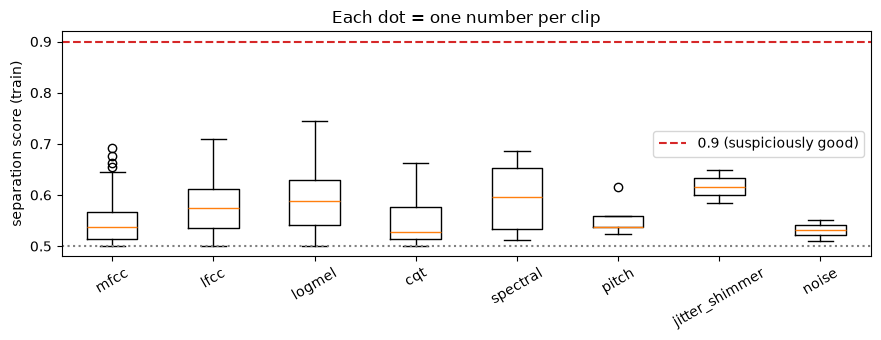

In [16]:
fig, ax = plt.subplots(figsize=(9, 3.5))
data = [auc[auc.group == f]["separation"].dropna() for f in FEATURES]
ax.boxplot(data, tick_labels=list(FEATURES))
ax.axhline(0.5, color="gray", linestyle=":")
ax.axhline(0.9, color="tab:red", linestyle="--", label="0.9 (suspiciously good)")
ax.set_ylabel("separation score (train)")
ax.set_title("Each dot = one number per clip")
ax.legend()
plt.xticks(rotation=30)
plt.tight_layout()

In [17]:
# The 15 numbers that separate real from fake best
auc.sort_values("separation", ascending=False).head(15)[["train", "dev", "separation"]].round(3)

,train,dev,separation
logmel:logmel79:mean,0.255,0.269,0.745
lfcc:lfcc18:mean,0.290,0.294,0.710
lfcc:lfcc0:mean,0.300,0.304,0.700
logmel:logmel29:mean,0.308,0.368,0.692
mfcc:mfcc0:mean,0.309,0.313,0.691
lfcc:lfcc5:mean,0.689,0.709,0.689
spectral:flatness:mean,0.315,0.353,0.685
logmel:logmel30:mean,0.317,0.359,0.683
logmel:logmel28:mean,0.323,0.344,0.677
mfcc:mfcc3:std,0.676,0.670,0.676


## Do the Scores Hold on Dev?

If a number separates real from fake on train but not on dev, it learned something specific to the train clips. Each dot below is one number, plotted by its raw score on train and on dev. Dots near the diagonal behave the same on both. A dot on the opposite side of 0.5 flips direction, so higher values are fake on one set and real on the other.

correlation between train and dev scores: 0.934
numbers that flip direction on dev (train score more than 0.05 from 0.5): 1


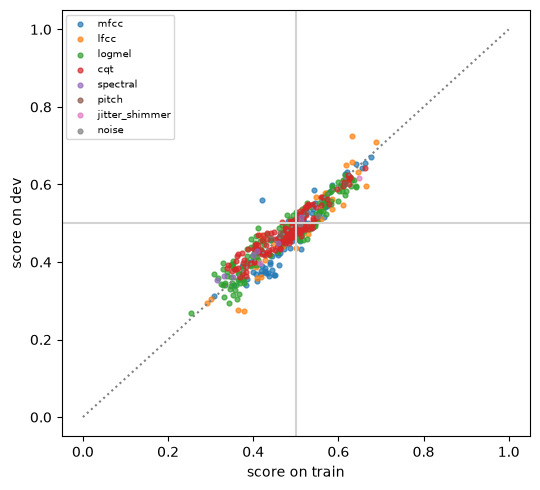

In [18]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for f in FEATURES:
    sub = auc[auc.group == f]
    ax.scatter(sub["train"], sub["dev"], s=12, alpha=0.7, label=f)
ax.plot([0, 1], [0, 1], color="gray", linestyle=":")
ax.axhline(0.5, color="lightgray")
ax.axvline(0.5, color="lightgray")
ax.set_xlabel("score on train")
ax.set_ylabel("score on dev")
ax.legend(fontsize=7, loc="upper left")
plt.tight_layout()

ok = auc[["train", "dev"]].dropna()
flipped = ok[((ok["train"] - 0.5) * (ok["dev"] - 0.5) < 0) & ((ok["train"] - 0.5).abs() > 0.05)]
print(f"correlation between train and dev scores: {ok['train'].corr(ok['dev']):.3f}")
print(f"numbers that flip direction on dev (train score more than 0.05 from 0.5): {len(flipped)}")

## Features to Watch

The noise features are the ones most likely to be a dataset shortcut, because they describe the recording, not the voice. The voiced fraction and spectral flux are also shown, since they relate to how steady the sound is.

In [19]:
watch = ["noise:noise_mean_db", "noise:noise_std_db", "pitch:voiced_fraction",
         "spectral:flux:mean", "spectral:flux:std"]
auc.loc[watch, ["train", "dev", "separation"]].round(3)

,train,dev,separation
noise:noise_mean_db,0.511,0.498,0.511
noise:noise_std_db,0.551,0.519,0.551
pitch:voiced_fraction,0.615,0.602,0.615
spectral:flux:mean,0.459,0.449,0.541
spectral:flux:std,0.353,0.361,0.647


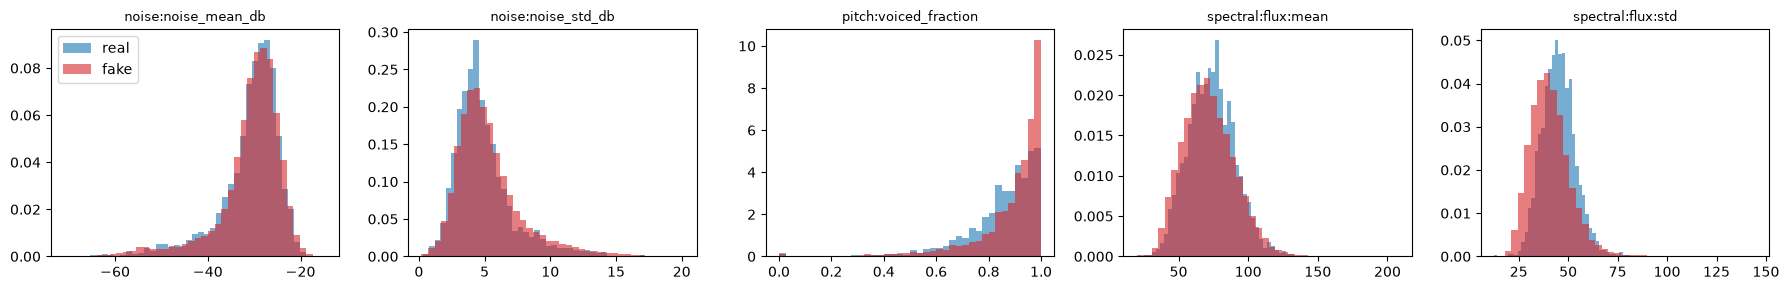

In [20]:
fig, axes = plt.subplots(1, len(watch), figsize=(18, 3))
for ax, col in zip(axes, watch):
    for label in (REAL, FAKE):
        vals = summary["train"][col][labels["train"]["label"] == label].dropna()
        ax.hist(vals, bins=40, alpha=0.6, density=True, color=COLORS[label], label=NAMES[label])
    ax.set_title(col, fontsize=9)
axes[0].legend()
plt.tight_layout()

In [21]:
suspicious = auc[auc["separation"] > 0.9]
print(f"{len(suspicious)} of {len(auc)} numbers score above 0.9 on train")
suspicious.groupby("group").size()

0 of 505 numbers score above 0.9 on train


Series([], dtype: int64)

## Summary

A score of 0.5 means a number tells us nothing, and 1.0 means it separates real from fake perfectly. Each number was tested on its own. The scores below are for train, with dev in brackets where it matters.

| Question | Finding | What we do about it |
|---|---|---|
| Is any single number too good to be true? | No. None of the 505 numbers scores above 0.9. The best is 0.745 (the highest-frequency mel band, average). | Nothing. A model combines many numbers, so moderate scores on their own are expected. |
| Do the noise features leak the label? | No. Noise mean scores 0.511 and noise spread 0.551, close to no information. | Keep them for now. They add little on their own. |
| Do the scores hold on dev? | Yes. The train and dev scores have a correlation of 0.934, and only 1 of 505 numbers flips direction. | The features should carry over to dev. |
| Which groups separate best? | The mel spectrogram (best 0.745), LFCC (0.710), MFCC (0.691), spectral (0.685) and jitter/shimmer (0.649). The top numbers mostly describe overall energy and the highest frequencies. | Keep these. |
| Does the "more regular" look from the first notebook show up? | Partly. The spread of spectral flux scores 0.647, and fakes have the lower spread, so their frame-to-frame change is steadier. The average flux scores only 0.541. | Keep the spectral features. |
| Is pitch useful? | Weakly. The voiced fraction scores 0.615, and fakes have more frames with a pitch. | Keep it for train and dev. Decide on 2021 after the phone-effects check. |
| Which groups look weakest? | CQT (best 0.662, median 0.528) and the noise features (best 0.551). | Candidates to drop, but see below. |

**Not covered yet:** each number was tested alone, so a group that looks weak here could still help in combination. Dropping features should wait for a model. These scores also come from clean audio, so the phone-effects check on dev is still to do.